### Telecom Customer Churn & Revenue Retention Analysis

***Tasks***

1. Importing Libraries
2. Loading the dataset
3. Initial Exploration
4. Data Cleaning
5. Data Analysis


**Task 1: Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

**Task 2: Loading the dataset**

In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

**Task 3: Initial Exploration**

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
# Statistical Summary
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Task 4: Data Cleaning**

In [ ]:
# Null Values
df.isnull().sum() #No Null values found which is strange for Totalcharges datatype

#There are 11 Null values in the TotalCharges column stored as whitespace
(df['TotalCharges'].astype(str).str.strip() == '').sum()

#Converting white space into proper missing values
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', pd.NA, regex=True)

#Checking missing values again
df.isnull().sum() #11 Null values found

#Displaying the Null values
df[df['TotalCharges'].isnull()]

#For every 0 tenure there is Null values in TotalCharges
#This suggests they are newly joined customers who have not yet accumulated any charges
# We can reasonably treat their TotalCharges as 0, because it represents accumulated charges—not their recurring monthly bill

#Lets convert TotalCharges to a numeric data type
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

#Lets replace missing TotalCharges with zero
df['TotalCharges'] = df['TotalCharges'].fillna(0)

#Lets verify the changes
df['TotalCharges'].isnull().sum()
#No null values found

#Lets check the data type
df['TotalCharges'].dtype
#I reloaded the df.describe() to get the new TotalCharges statistical summary as it was not there due to its data type errors


dtype('float64')

In [ ]:
# Duplicates
df.duplicated().sum()
# No Duplicate values found

np.int64(0)

In [ ]:
# Type Casting (Changing data types)
df.dtypes
# No incorrect data type found

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [ ]:
# Checking for Wrong data in categorical columns
df['gender'].value_counts()

df['Contract'].value_counts()

df['PaymentMethod'].value_counts()

df['InternetService'].value_counts()

df['Churn'].value_counts()

df['Partner'].value_counts()

df['Dependents'].value_counts()
# No Wrong data in categorical columns found


Dependents
No     4933
Yes    2110
Name: count, dtype: int64

**Task 5: Data Analysis**

**Section A: Exploratory Data Analysis (EDA)**

***Customer Demographics***

In [ ]:
# Customer Demographics Summary (Statistical Summary)
df[['gender', 'SeniorCitizen', 'Partner', 'Dependents']].describe()

,SeniorCitizen
count,7043.000000
mean,0.162147
std,0.368612
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [ ]:
# Customer Counts According to Demographic Categories
# Gender distribution
df['gender'].value_counts()

# Senior citizen distribution
df['SeniorCitizen'].value_counts()

# Partner distribution
df['Partner'].value_counts()

# Dependents distribution
df['Dependents'].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

***Customer Account Information***

In [ ]:
# Customer Counts According to Account Categories
# Contract type distribution
df['Contract'].value_counts()

# Tenure distribution
df['tenure'].value_counts().sort_index()

# Paperless billing distribution
df['PaperlessBilling'].value_counts()

PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

In [ ]:
# Customer Tenure Summary
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

***Customer Services***

In [ ]:
# Customer Counts According to Service Categories
# Phone service
df['PhoneService'].value_counts()

# Multiple lines
df['MultipleLines'].value_counts()

# Internet service
df['InternetService'].value_counts()

# Additional services
df['OnlineSecurity'].value_counts()

df['OnlineBackup'].value_counts()

df['DeviceProtection'].value_counts()

df['TechSupport'].value_counts()

df['StreamingTV'].value_counts()

df['StreamingMovies'].value_counts()

StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64

***Customer Billing and Revenue***

In [ ]:
# Customer Counts According to Payment Methods
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [ ]:
# Monthly Charges Statistical Summary
df['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [ ]:
# Total Charges Statistical Summary
df['TotalCharges'].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

In [ ]:
# Monthly Revenue Overview
df['MonthlyCharges'].sum() # Calculates the sum of monthly charges across all customers

np.float64(456116.6)

***Customer Churn***

In [ ]:
# Customer Counts According to Churn Status
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
# Customer Churn Percentage Distribution
df['Churn'].value_counts(normalize=True) * 100 # Calculates the percentage of customers who churned and those who remained

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [ ]:
# Overall Customer Churn Rate
churn_rate = (df['Churn'].value_counts(normalize=True)['Yes']) * 100

print(f"Overall Customer Churn Rate: {churn_rate:.2f}%")

Overall Customer Churn Rate: 26.54%


***Numerical Variables Overview***

In [ ]:
# Statistical Summary of Numerical Variables
df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [ ]:
# Correlation Between Numerical Variables
df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].corr()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000



**Section B: Business Questions**

Qn 1.What is the overall customer churn rate?

Qn 2.What is the company's total monthly revenue?

Qn 3.Which customer segments have the highest churn rates?

Qn 4.How does tenure influence customer churn?

Qn 5.Which contract types experience the highest churn?

Qn 6.Does payment method relate to customer churn?

Qn 7.Which customer segments generate the highest revenue?

Qn 8.How does average monthly spending differ between churned and retained customers?

Qn 9.Does having additional services relate to customer retention?

Qn 10.Which customer characteristics are most strongly associated with churn?

Qn 11: What strategies could management implement to reduce customer churn?



### Univariate Analysis
**Qn 1. What is the overall customer churn rate?**

Overall Customer Churn Rate: 26.54%


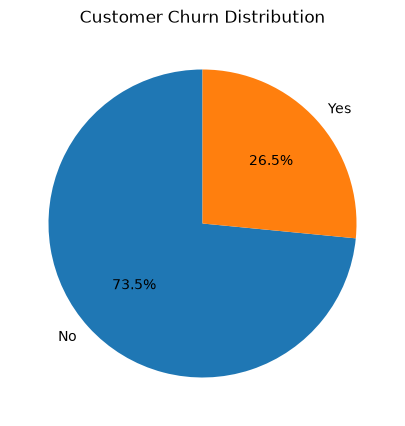

In [ ]:
# Overall customer churn rate
churn_rate = (df['Churn'] == 'Yes').mean() * 100

print(f"Overall Customer Churn Rate: {churn_rate:.2f}%")

# Customer Churn Distribution Plot
import matplotlib.pyplot as plt

# Calculate customer counts
churn_counts = df['Churn'].value_counts()

# Plot of Customer Churn distribution
plt.figure(figsize=(5, 5))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Churn Distribution')
plt.show()

**Qn 2.What is the company's total monthly revenue?**

Total Monthly Revenue: $456,116.60


<Figure size 600x400 with 0 Axes>

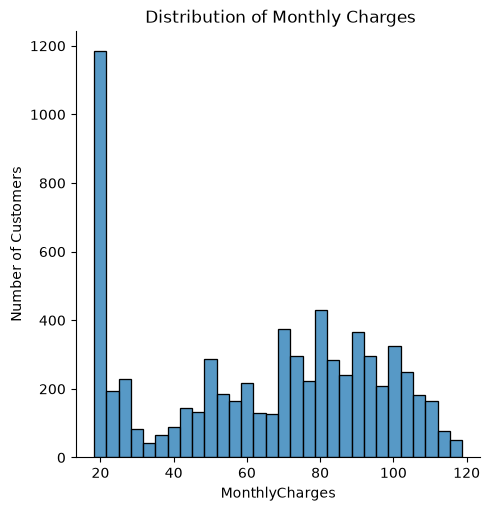

In [ ]:
# Calculate total monthly revenue
monthly_revenue = df['MonthlyCharges'].sum()

print(f"Total Monthly Revenue: ${monthly_revenue:,.2f}")

# Plot of Total Monthly Charges distribution
plt.figure(figsize=(6, 4))
sns.displot(data = df, x  = 'MonthlyCharges', bins = 30)
plt.title(' Distribution of Monthly Charges')
plt.ylabel("Number of Customers")
plt.show()

### Bivariate Analysis

**Qn 3.Which customer segments have the highest churn rates?**


Churn Rate by gender:
gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

Churn Rate by SeniorCitizen:
SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64

Churn Rate by Partner:
Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Churn Rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64


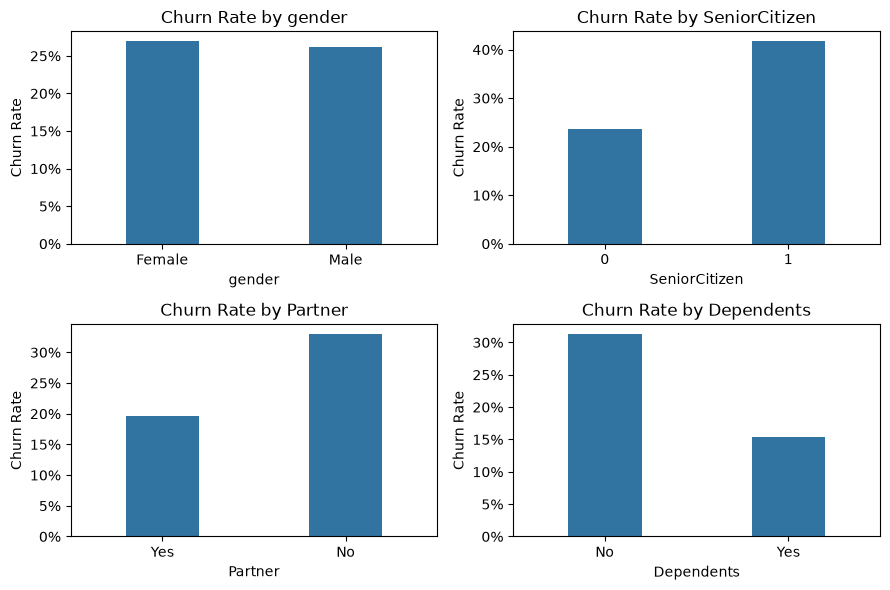

In [132]:
# Customer churn rates by demographic segments
demographic_columns = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']

for column in demographic_columns:
    churn_rate = df.groupby(column)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

    print(f"\nChurn Rate by {column}:")
    print(churn_rate.round(2))

    # Plots of Customer Churn rates by Customer Segments
fig, axes = plt.subplots(2, 2, figsize=(9, 6))

for column, ax in zip(demographic_columns, axes.flatten()):
    sns.barplot(
        data=df,
        x=column,
        y=df['Churn'].eq('Yes').astype(int),
        ax=ax,
        errorbar=None,
        width=0.4
    )

    ax.set_title(f'Churn Rate by {column}')
    ax.set_ylabel('Churn Rate')
    ax.set_xlabel(column)

    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f'{y:.0%}')
    )

plt.tight_layout()
plt.show()

**Qn 4.How does tenure influence customer churn?**

TenureGroup
new_customers            47.44
medium-term_customers    23.64
long-term_customers       9.51
Name: Churn, dtype: float64


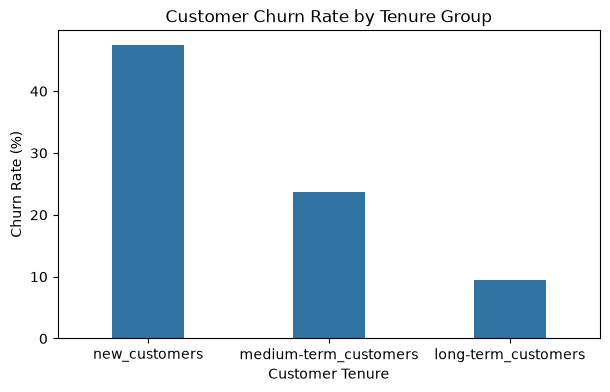

In [127]:
# Group customers by tenure
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 48, 72],
    labels=['new_customers', 'medium-term_customers', 'long-term_customers']
)

# Calculate churn rate by tenure group
churn_by_tenure = df.groupby('TenureGroup', observed=False)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(churn_by_tenure.round(2))

# Plot of Customer Churn rate by Tenure group
plt.figure(figsize=(7, 4))

sns.barplot(
    x=churn_by_tenure.index,
    y=churn_by_tenure.values,
    width=0.4
)

plt.title('Customer Churn Rate by Tenure Group')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')

plt.show()


**Q5. Which contract types experience the highest churn?**

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


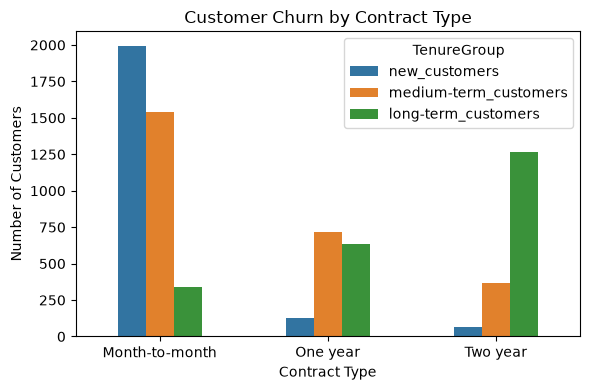

In [137]:
# Churn rate by Contract type
churn_by_contract = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean()*100)

print(churn_by_contract.round(2))

# Plot of Customer Churn rate by contract type 
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Contract',
    hue='TenureGroup',
    width=0.5
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

**Qn 6.Does payment method relate to customer churn?**


PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


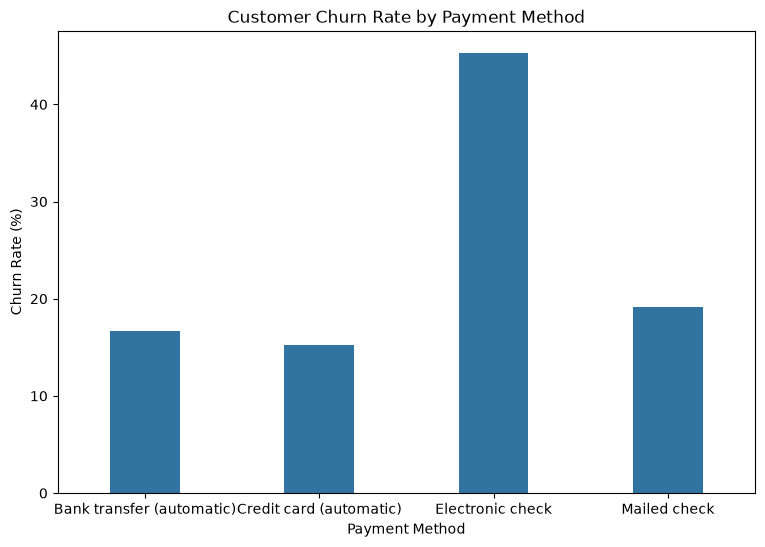

In [129]:
# Churn rate by payment method
churn_by_payment = df.groupby('PaymentMethod')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

print(churn_by_payment.round(2))

# Plot of Customer Churn rate ralation to Payment method
plt.figure(figsize=(9,6))

sns.barplot(
    x = churn_by_payment.index,
    y = churn_by_payment.values,
    width = 0.4
)

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')

plt.show()

**Qn 7.Which customer segments generate the highest revenue?**

gender
Female    227432.4
Male      228684.2
Name: MonthlyCharges, dtype: float64
SeniorCitizen
0    364961.75
1     91154.85
Name: MonthlyCharges, dtype: float64
Partner
No     225541.75
Yes    230574.85
Name: MonthlyCharges, dtype: float64
Dependents
No     330524.85
Yes    125591.75
Name: MonthlyCharges, dtype: float64


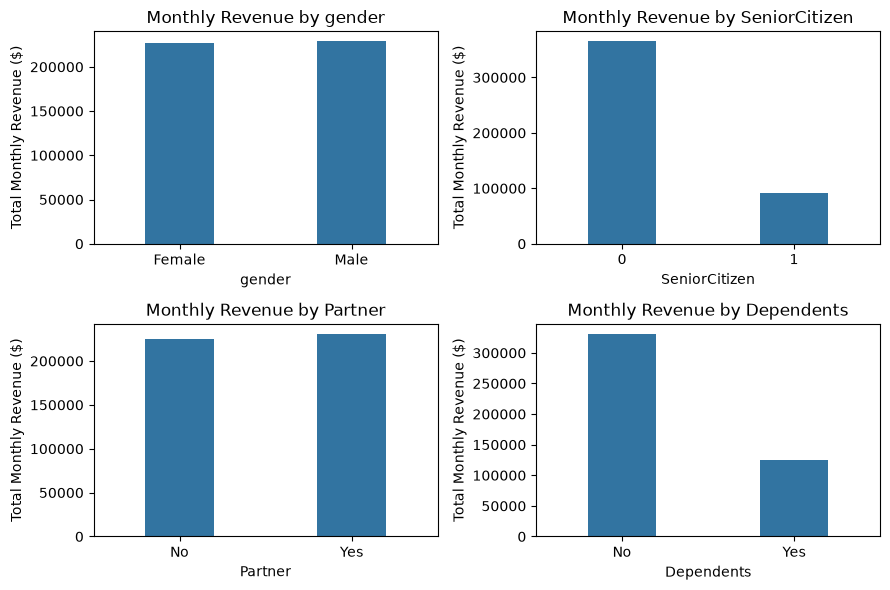

In [ ]:
# Revenue by gender
revenue_by_gender = df.groupby('gender')['MonthlyCharges'].sum()

print(revenue_by_gender)

# Revenue by senior citizen status
revenue_by_senior_citizen = df.groupby('SeniorCitizen')['MonthlyCharges'].sum()

print(revenue_by_senior_citizen)

# Revenue by partner status
revenue_by_partner = df.groupby('Partner')['MonthlyCharges'].sum()

print(revenue_by_partner)

# Revenue by dependent status
revenue_by_dependents = df.groupby('Dependents')['MonthlyCharges'].sum()

print(revenue_by_dependents)

# Plots of total monthly revenue for each demographic segment
demographic_columns = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']

fig, axes = plt.subplots(2, 2, figsize=(9, 6))

for column, ax in zip(demographic_columns, axes.flatten()):
    revenue = df.groupby(column)['MonthlyCharges'].sum()

    sns.barplot(
        x=revenue.index,
        y=revenue.values,
        ax=ax,
        width=0.4
    )

    ax.set_title(f'Monthly Revenue by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Total Monthly Revenue ($)')

plt.tight_layout()
plt.show()

**Qn 8.How does average monthly spending differ between churned and retained customers?**

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


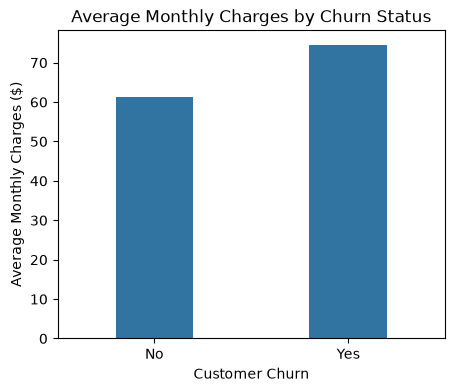

In [93]:
avg_spending = df.groupby('Churn')['MonthlyCharges'].mean()

print(avg_spending.round(2))

# Plot of avarage monthly charges by Churn status
plt.figure(figsize=(5, 4))

sns.barplot(
    x=avg_spending.index,
    y=avg_spending.values,
    width=0.4
)

plt.title('Average Monthly Charges by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Average Monthly Charges ($)')
plt.show()

**Qn 9.Does having additional services relate to customer retention?**


Churn Rate by OnlineSecurity:
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

Churn Rate by OnlineBackup:
OnlineBackup
No                     39.93
No internet service     7.40
Yes                    21.53
Name: Churn, dtype: float64

Churn Rate by DeviceProtection:
DeviceProtection
No                     39.13
No internet service     7.40
Yes                    22.50
Name: Churn, dtype: float64

Churn Rate by TechSupport:
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64

Churn Rate by StreamingTV:
StreamingTV
No                     33.52
No internet service     7.40
Yes                    30.07
Name: Churn, dtype: float64

Churn Rate by StreamingMovies:
StreamingMovies
No                     33.68
No internet service     7.40
Yes                    29.94
Name: Churn, dtype: float64


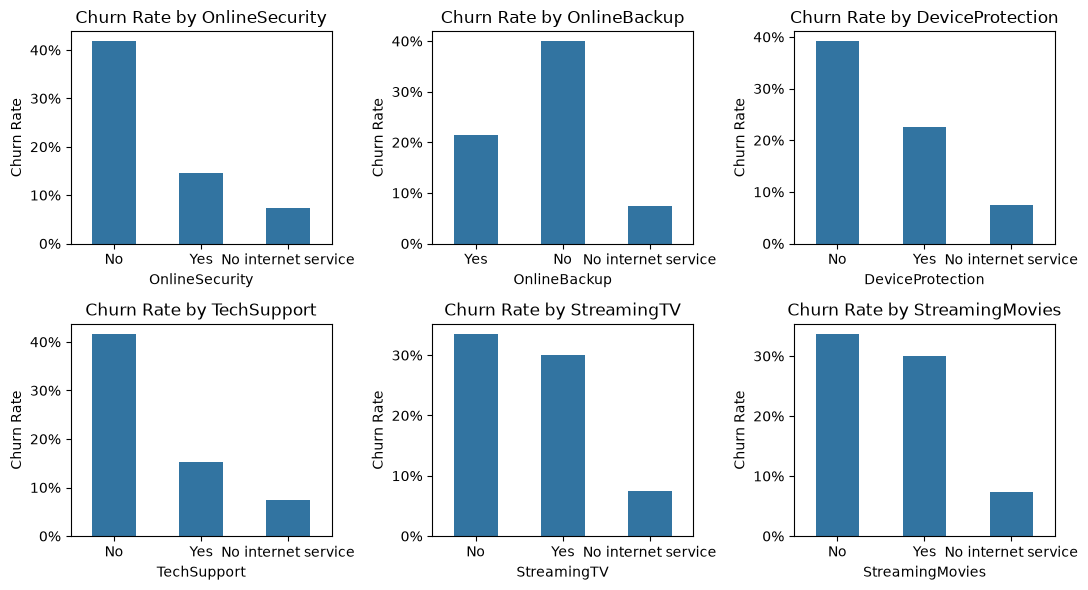

In [131]:
service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

for column in service_columns:
    churn_rate = df.groupby(column)['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

    print(f'\nChurn Rate by {column}:')
    print(churn_rate.round(2))

# Plots of Customer services relation to customer rentention
fig, axes = plt.subplots(2, 3, figsize=(11, 6))

for column, ax in zip(service_columns, axes.flatten()):
    sns.barplot(
        data=df,
        x=column,
        y=df['Churn'].eq('Yes').astype(int),
        ax=ax,
        errorbar=None,
        width=0.5
    )

    ax.set_title(f'Churn Rate by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Churn Rate')
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f'{y:.0%}')
    )

plt.tight_layout()
plt.show()

**Qn 10.Which customer characteristics are most strongly associated with churn?**

Churn             1.000000
MonthlyCharges    0.193356
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn, dtype: float64


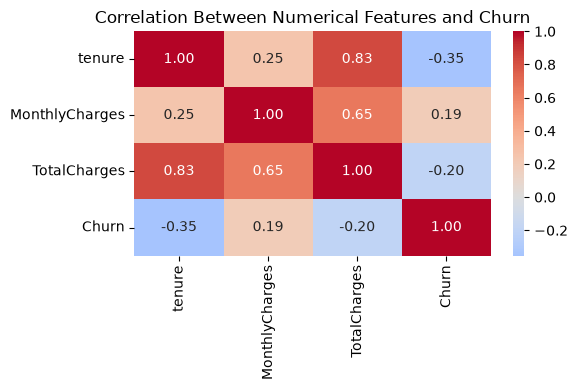

In [113]:
# Convert Yes and No in Churn columns to 1 and 0
corr_df = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()

corr_df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# Calculate correlations

corr_matrix = corr_df.corr()

print(corr_matrix['Churn'].sort_values(ascending=False))

# Correlation Visualization of Customer Characteristics that are associated with Churn
plt.figure(figsize=(6, 4))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Between Numerical Features and Churn')
plt.tight_layout()
plt.show()

**Qn 11: What strategies could management implement to reduce customer churn?**

| Key Findings | Proposed Management Strategies |
|---|---|
| A considerable proportion of customers discontinue their subscriptions, indicating a customer retention challenge. | Develop customer retention programmes focused on identifying and engaging customers who are likely to leave. |
| Senior citizens experience higher churn than younger customers. Customers without partners and those without dependents also experience higher churn. Gender differences are relatively small. | Investigate the needs of these customer segments and develop targeted retention campaigns based on their preferences and service requirements. |
| New customers are considerably more likely to churn than medium-term and long-term customers. | Introduce structured onboarding programmes, early customer engagement and incentives to encourage new customers to remain subscribed. |
| Customers on month-to-month contracts experience substantially higher churn (especially newer customers) than those on longer-term contracts. | Encourage customers (especially newer customers) to adopt longer-term contracts through attractive discounts, loyalty benefits and flexible subscription options. |
| Customers using electronic checks experience considerably higher churn than customers using other payment methods. | Investigate potential payment difficulties and encourage the adoption of convenient and reliable payment methods. |
| Churned customers have higher average monthly spending than retained customers. | Review pricing structures, introduce affordable service packages and ensure customers perceive sufficient value from their subscriptions. |
| Customers without additional services generally experience higher churn than customers subscribed to services such as Online Security, Online Backup and Tech Support. | Promote complementary services through affordable bundles and targeted subscription offers. |
| Customers with longer tenure tend to have lower churn. | Strengthen customer loyalty programmes. |
| Customers without dependents generate the largest aggregate monthly revenue among the demographic groups analysed. Customers with partners also generate slightly more aggregate revenue than those without partners. | Monitor revenue contributions across customer segments and develop appropriate retention initiatives for valuable customer groups. |

### Conclusion
The analysis indicates that customer churn is associated with several customer characteristics and account-related factors. New customers, month-to-month contract subscribers, electronic check users and customers without additional services represent important areas for further investigation.

Management should prioritise early customer engagement, competitive pricing, longer-term contracts, convenient payment options and targeted retention initiatives.

The proposed strategies should be tested and monitored to determine their actual effectiveness in reducing customer churn and protecting recurring revenue.